# Prediksi Rata-Rata Waktu Bermain Game Steam Menggunakan Random Forest Regression
### Algoritma: Random Forest Regression

Dataset : https://www.kaggle.com/datasets/fronkongames/steam-games-dataset




---
## Tahap 1: Data Loading

In [1]:
import pandas as pd

# Memuat dataset games.csv (11 kolom bersih)
df = pd.read_csv('games.csv')
print(f"Dataset berhasil dimuat: {df.shape[0]:,} baris dan {df.shape[1]} kolom.")
df.head()

Dataset berhasil dimuat: 125,855 baris dan 11 kolom.


,Name,Required age,Price,DLC count,Windows,Mac,Linux,Achievements,Average playtime forever,Categories,Genres
0,Black Dragon Mage Playtest,0,0.00,0,True,False,False,0,0,NaN,NaN
1,Supipara - Chapter 1 Spring Has Come!,0,5.24,0,True,False,False,0,8,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure
2,Mystery Solitaire The Black Raven,0,4.99,0,True,True,False,0,0,"Single-player,Family Sharing",Casual
3,버튜버 파라노이아 - Vtuber Paranoia,0,8.99,1,True,False,False,19,0,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation"
4,Maze Quest VR,0,4.99,0,True,False,False,0,0,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access"


---
## Tahap 2 : Data Cleaning dan Transformation

In [2]:
# 1. Ringkasan informasi tipe data dan non-null count
df.info()

# 2. Statistik deskriptif dari seluruh kolom
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 11 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Name                      125854 non-null  str    
 1   Required age              125855 non-null  int64  
 2   Price                     125855 non-null  float64
 3   DLC count                 125855 non-null  int64  
 4   Windows                   125855 non-null  bool   
 5   Mac                       125855 non-null  bool   
 6   Linux                     125855 non-null  bool   
 7   Achievements              125855 non-null  int64  
 8   Average playtime forever  125855 non-null  int64  
 9   Categories                116889 non-null  str    
 10  Genres                    117432 non-null  str    
dtypes: bool(3), float64(1), int64(4), str(3)
memory usage: 20.9 MB


,Name,Required age,Price,DLC count,Windows,Mac,Linux,Achievements,Average playtime forever,Categories,Genres
count,125854,125855.000000,125855.000000,125855.000000,125855,125855,125855,125855.000000,1.258550e+05,116889,117432
unique,124644,NaN,NaN,NaN,2,2,2,NaN,NaN,14058,2922
top,Shadow of the Tomb Raider: Definitive Edition,NaN,NaN,NaN,True,False,False,NaN,NaN,"Single-player,Family Sharing","Casual,Indie"
freq,20,NaN,NaN,NaN,125811,104136,109786,NaN,NaN,23878,6912
mean,NaN,0.165365,4.811174,0.535434,NaN,NaN,NaN,17.922220,2.027568e+02,NaN,NaN
std,NaN,1.642666,12.489329,14.328417,NaN,NaN,NaN,139.696425,1.107222e+04,NaN,NaN
min,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000e+00,NaN,NaN
25%,NaN,0.000000,0.590000,0.000000,NaN,NaN,NaN,0.000000,0.000000e+00,NaN,NaN
50%,NaN,0.000000,2.390000,0.000000,NaN,NaN,NaN,2.000000,0.000000e+00,NaN,NaN
75%,NaN,0.000000,5.545000,0.000000,NaN,NaN,NaN,19.000000,0.000000e+00,NaN,NaN


In [3]:
# 1. Filter hanya game yang memiliki waktu bermain tercatat (> 0 menit)
df_played = df[df["Average playtime forever"] > 0].copy()
print(f"Total data game valid yang pernah dimainkan: {len(df_played):,} baris.")

# 2. Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = df_played.isnull().sum()
print("\nKolom dengan nilai hilang:")
print(missing_values[missing_values > 0])

# 3. Imputasi nilai hilang pada kolom kategorikal (Categories, Genres, Name)
categorical_cols = df_played.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    mode_val = df_played[col].mode()[0] if not df_played[col].mode().empty else "Unknown"
    df_played[col] = df_played[col].fillna(mode_val)

# 4. Imputasi nilai hilang pada kolom numerik dengan median (jika ada)
numeric_cols = df_played.select_dtypes(include=["number"]).columns
df_played[numeric_cols] = df_played[numeric_cols].fillna(df_played[numeric_cols].median())

# 5. Verifikasi ulang memastikan sudah tidak ada missing values
print(f"\nSisa missing values setelah penanganan: {df_played.isnull().sum().sum()}")
df = df_played

Total data game valid yang pernah dimainkan: 26,173 baris.

Kolom dengan nilai hilang:
Categories    143
Genres         69
dtype: int64

Sisa missing values setelah penanganan: 0


C:\Users\fajar\AppData\Local\Temp\ipykernel_83860\1945815636.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_played.select_dtypes(include=["object"]).columns


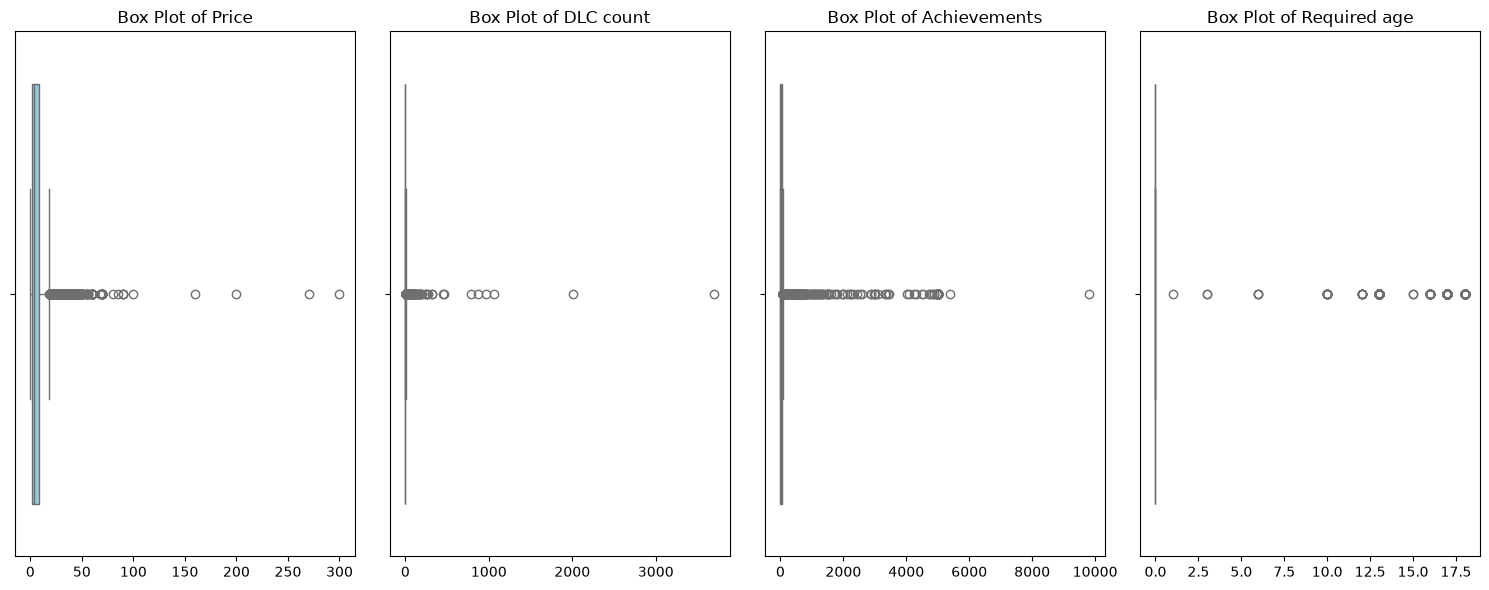

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Fitur numerik desain game yang diperiksa
features_to_check = ["Price", "DLC count", "Achievements", "Required age"]

plt.figure(figsize=(15, 6))
for i, feature in enumerate(features_to_check, 1):
    plt.subplot(1, 4, i)
    sns.boxplot(x=df[feature], color="skyblue")
    plt.title(f"Box Plot of {feature}")
    plt.xlabel("")

plt.tight_layout()
plt.show()

In [5]:
# Menerapkan Capping batas atas dan bawah berdasarkan IQR
features_capping = ["Price", "DLC count", "Achievements", "Average playtime forever"]

for col in features_capping:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Batasi nilai ke rentang wajar (Capping)
    df[col] = df[col].clip(lower=max(0, lower_bound), upper=upper_bound)

print("Capping Outlier berhasil diterapkan pada kolom:", features_capping)

Capping Outlier berhasil diterapkan pada kolom: ['Price', 'DLC count', 'Achievements', 'Average playtime forever']


In [6]:
# Pengecekan dan Penghapusan Duplikat
duplicates = df.duplicated()
print(f"Jumlah baris duplikat: {duplicates.sum()}")
if duplicates.sum() > 0:
    df = df.drop_duplicates()
    print("Baris duplikat berhasil dihapus.")

Jumlah baris duplikat: 4
Baris duplikat berhasil dihapus.


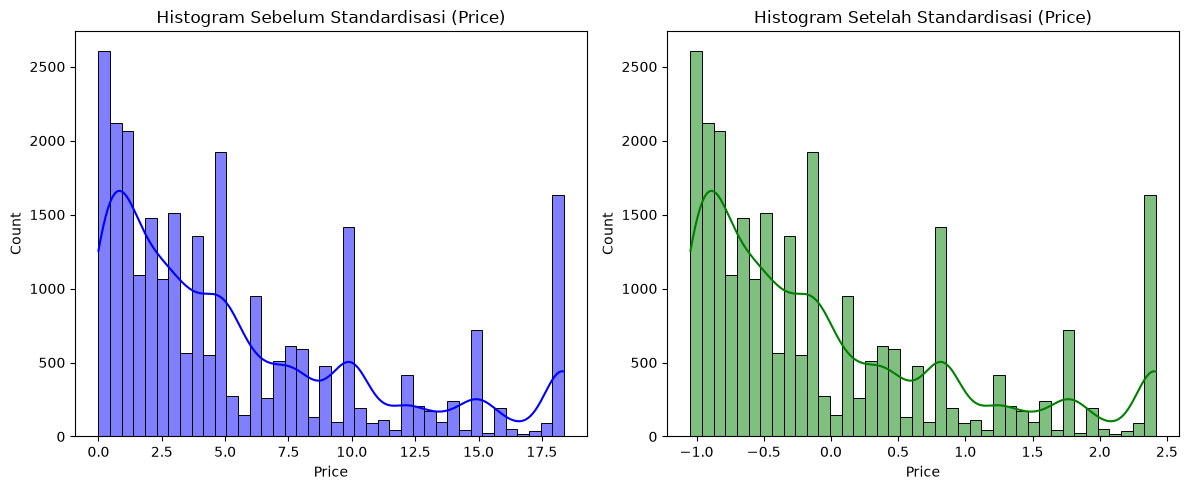

In [7]:
from sklearn.preprocessing import StandardScaler

features_to_scale = ["Price", "DLC count", "Achievements", "Required age"]

# Simpan nilai sebelum standardisasi untuk perbandingan
raw_feature = df[features_to_scale[0]].copy()

# Terapkan StandardScaler
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features_to_scale] = scaler.fit_transform(df[features_to_scale])

# Visualisasi Histogram Sebelum vs Setelah Standardisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(raw_feature, kde=True, color="blue")
plt.title(f"Histogram Sebelum Standardisasi ({features_to_scale[0]})")

plt.subplot(1, 2, 2)
sns.histplot(df_scaled[features_to_scale[0]], kde=True, color="green")
plt.title(f"Histogram Setelah Standardisasi ({features_to_scale[0]})")

plt.tight_layout()
plt.show()

In [8]:
# 1. Konversi boolean OS ke numerik biner (1 / 0)
df_scaled["Windows"] = df_scaled["Windows"].astype(int)
df_scaled["Mac"] = df_scaled["Mac"].astype(int)
df_scaled["Linux"] = df_scaled["Linux"].astype(int)

# 2. One-Hot Encoding pada 10 Genre terpopuler
genres_dummies = df_scaled["Genres"].str.get_dummies(sep=",")
top_10_genres = genres_dummies.sum().sort_values(ascending=False).head(10).index
genres_encoded = genres_dummies[top_10_genres].add_prefix("Genre_")

# 3. One-Hot Encoding pada Mode Gameplay Utama (Categories)
cat_dummies = df_scaled["Categories"].str.get_dummies(sep=",")
key_modes = ["Single-player", "Multi-player", "Co-op", "Steam Achievements", "Steam Cloud"]
available_modes = [c for c in key_modes if c in cat_dummies.columns]
categories_encoded = cat_dummies[available_modes].add_prefix("Mode_")

# 4. Gabungkan hasil encoding ke dataframe akhir
df_final = pd.concat([df_scaled, genres_encoded, categories_encoded], axis=1)

# 5. Hapus kolom teks mentah (Name, Categories, Genres)
cols_to_drop = ["Name", "Categories", "Genres"]
df_final = df_final.drop(columns=[col for col in cols_to_drop if col in df_final.columns])

print("Data Cleaning & Feature Engineering Murni Pre-Release Selesai!")
print(f"Dimensi dataset siap modeling: {df_final.shape}")
df_final.head()

Data Cleaning & Feature Engineering Murni Pre-Release Selesai!
Dimensi dataset siap modeling: (26169, 23)


,Required age,Price,DLC count,Windows,Mac,Linux,Achievements,Average playtime forever,Genre_Indie,Genre_Action,...,Genre_RPG,Genre_Strategy,Genre_Early Access,Genre_Free To Play,Genre_Sports,Mode_Single-player,Mode_Multi-player,Mode_Co-op,Mode_Steam Achievements,Mode_Steam Cloud
1,-0.186321,-0.057312,-0.644178,1,0,0,-0.971222,8,0,0,...,0,0,0,0,0,1,0,0,0,1
6,-0.186321,2.417578,0.540259,1,0,0,-0.971222,675,0,0,...,0,1,0,0,0,1,0,0,0,1
12,-0.186321,1.592614,2.316913,1,0,0,2.153774,489,0,0,...,0,1,0,0,0,1,1,0,1,1
17,-0.186321,-0.849277,-0.644178,1,0,0,-0.971222,203,0,1,...,0,0,0,0,0,1,0,0,0,0
19,-0.186321,0.084110,-0.644178,1,1,0,0.449230,88,0,0,...,0,0,0,0,0,1,0,0,0,0


---
## Tahap 3: Exploratory Data Analysis (EDA)


In [9]:
# Menyimpan alias df_lencoder agar sesuai dengan penamaan template dosen
df_lencoder = df_final.copy()
df_lencoder.head()

,Required age,Price,DLC count,Windows,Mac,Linux,Achievements,Average playtime forever,Genre_Indie,Genre_Action,...,Genre_RPG,Genre_Strategy,Genre_Early Access,Genre_Free To Play,Genre_Sports,Mode_Single-player,Mode_Multi-player,Mode_Co-op,Mode_Steam Achievements,Mode_Steam Cloud
1,-0.186321,-0.057312,-0.644178,1,0,0,-0.971222,8,0,0,...,0,0,0,0,0,1,0,0,0,1
6,-0.186321,2.417578,0.540259,1,0,0,-0.971222,675,0,0,...,0,1,0,0,0,1,0,0,0,1
12,-0.186321,1.592614,2.316913,1,0,0,2.153774,489,0,0,...,0,1,0,0,0,1,1,0,1,1
17,-0.186321,-0.849277,-0.644178,1,0,0,-0.971222,203,0,1,...,0,0,0,0,0,1,0,0,0,0
19,-0.186321,0.084110,-0.644178,1,1,0,0.449230,88,0,0,...,0,0,0,0,0,1,0,0,0,0


In [10]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
}).sort_values(by="Missing Values", ascending=False)

# Menampilkan kolom dengan missing values (jika ada)
kolom_missing = missing_data[missing_data["Missing Values"] > 0]
if len(kolom_missing) == 0:
    print("Luar biasa! Tidak ada missing values yang tersisa (Data 100 persen lengkap).")
else:
    print(kolom_missing)

Luar biasa! Tidak ada missing values yang tersisa (Data 100 persen lengkap).


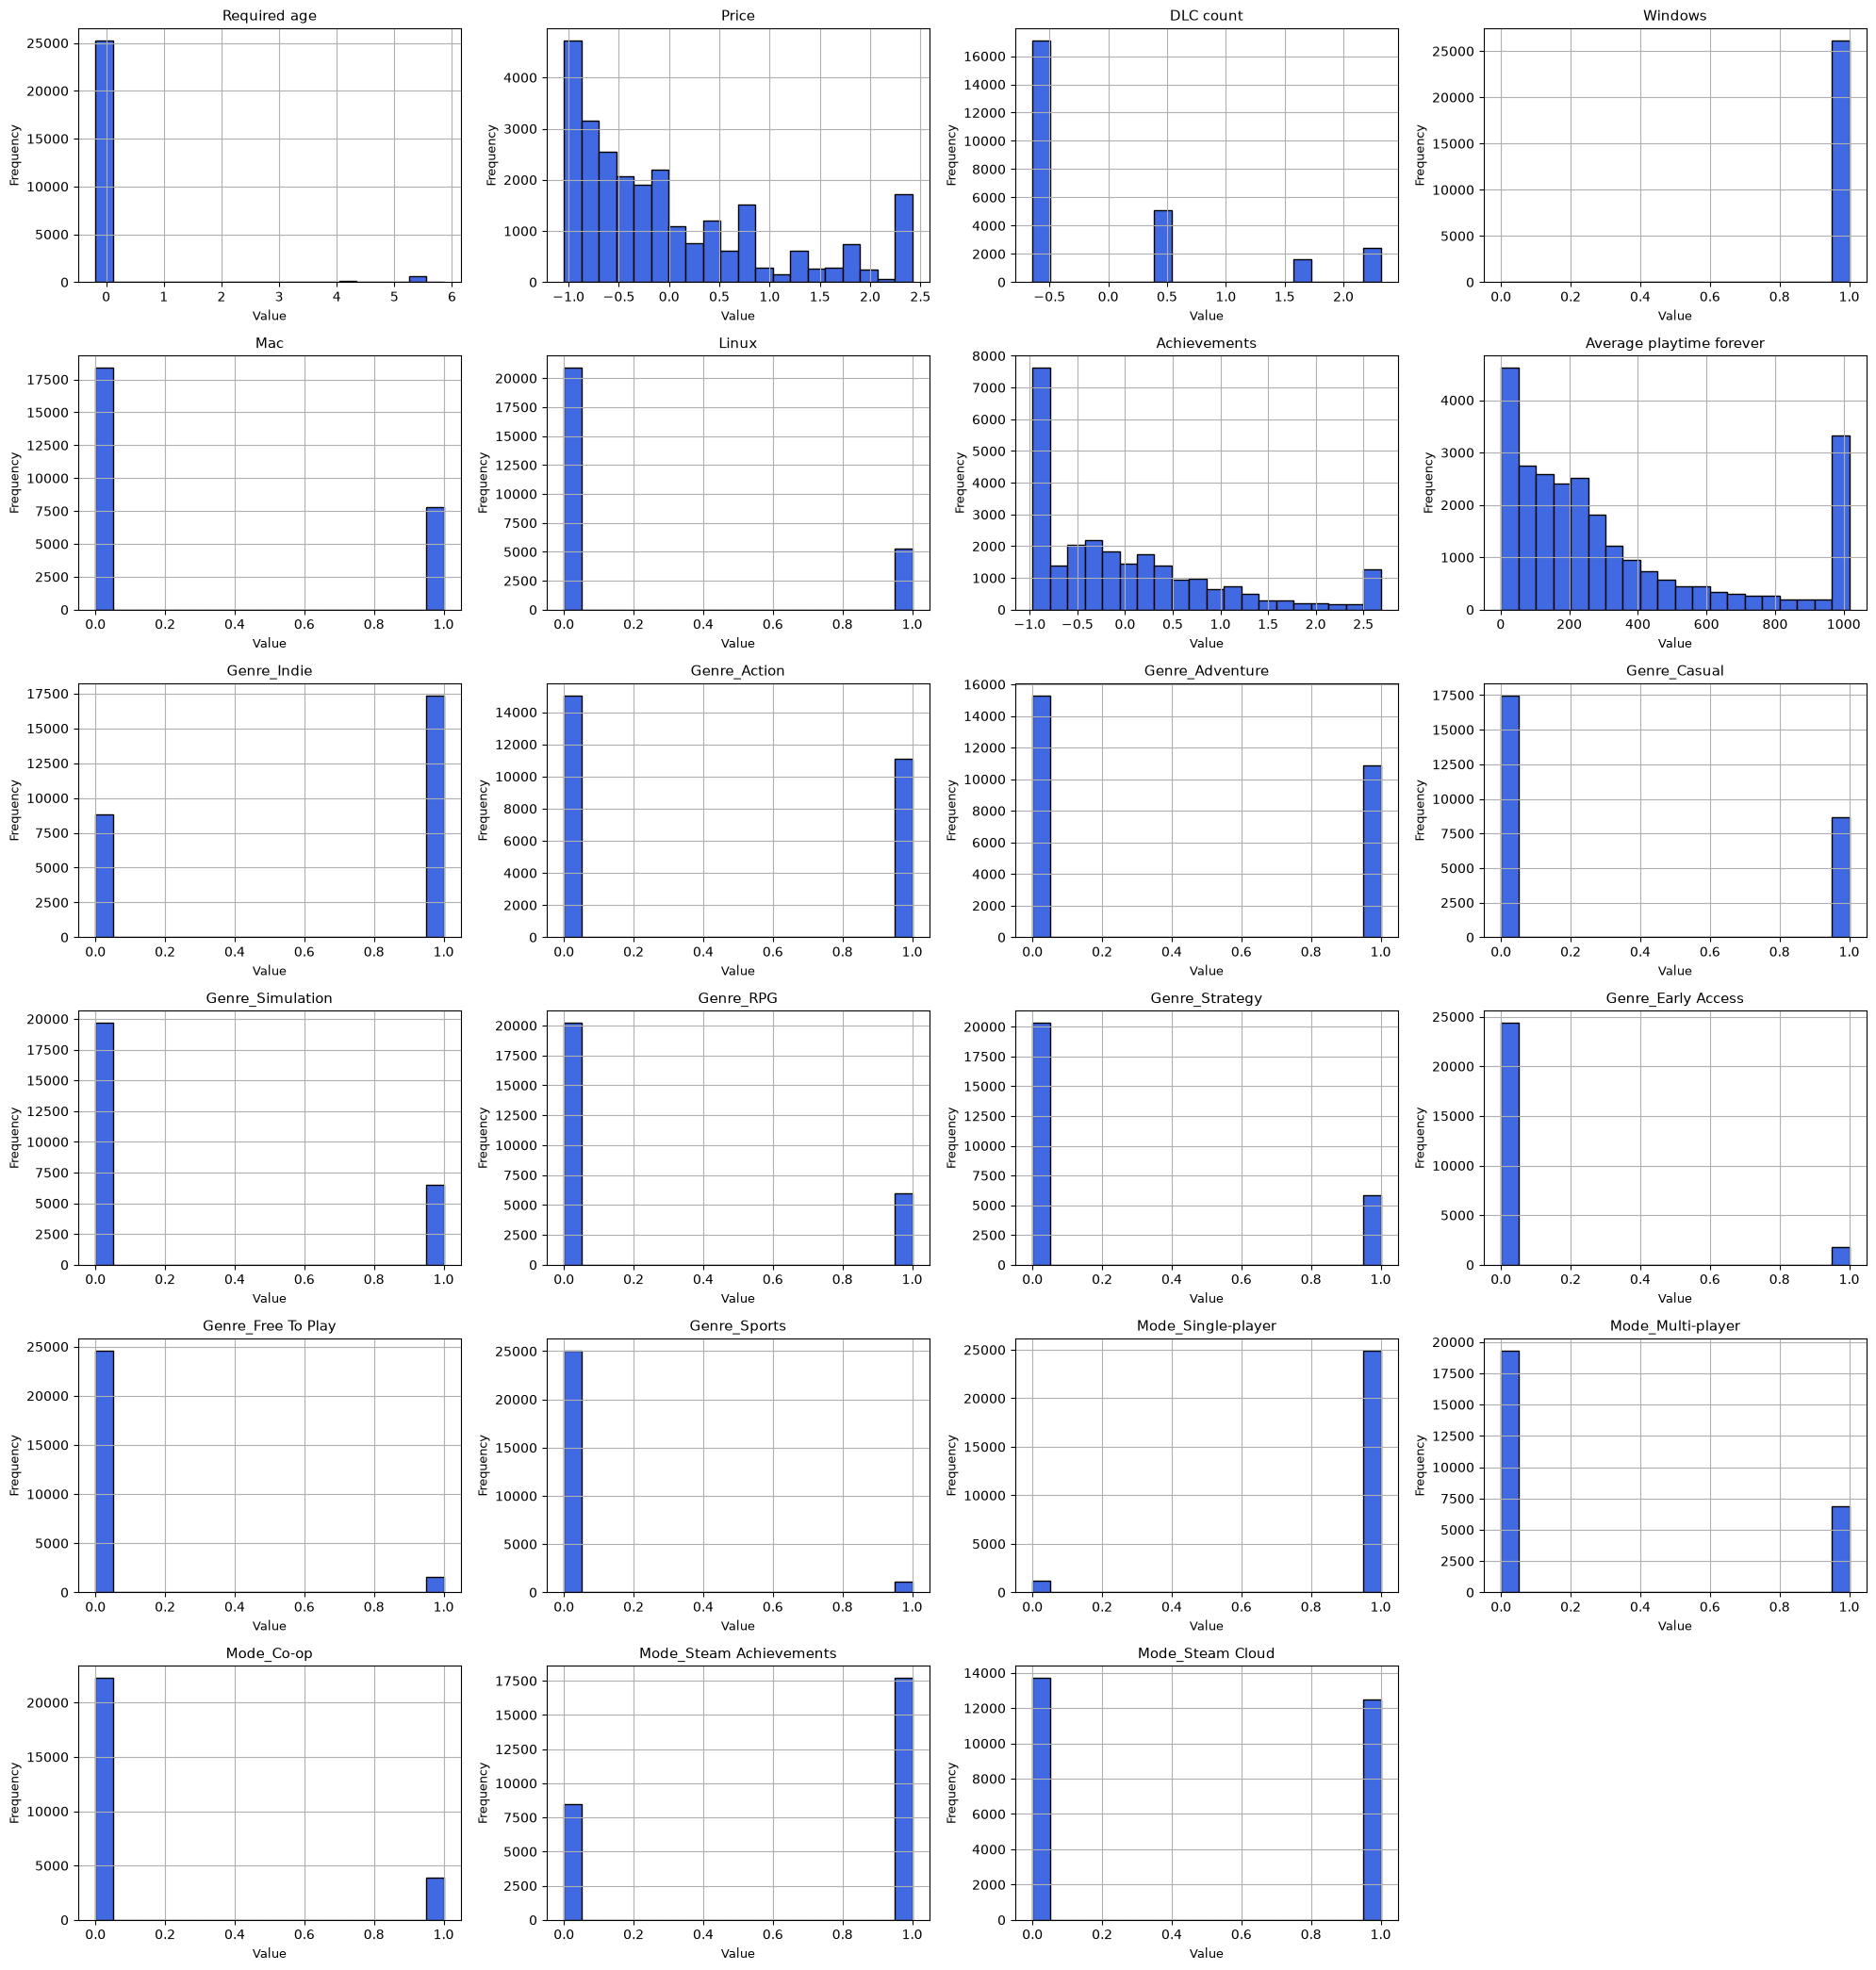

In [11]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4
n_rows = -(-num_vars // n_cols)

# Membuat subplot grid histogram
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor="black", color="royalblue")
    axes[i].set_title(column, fontsize=11)
    axes[i].set_xlabel("Value", fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

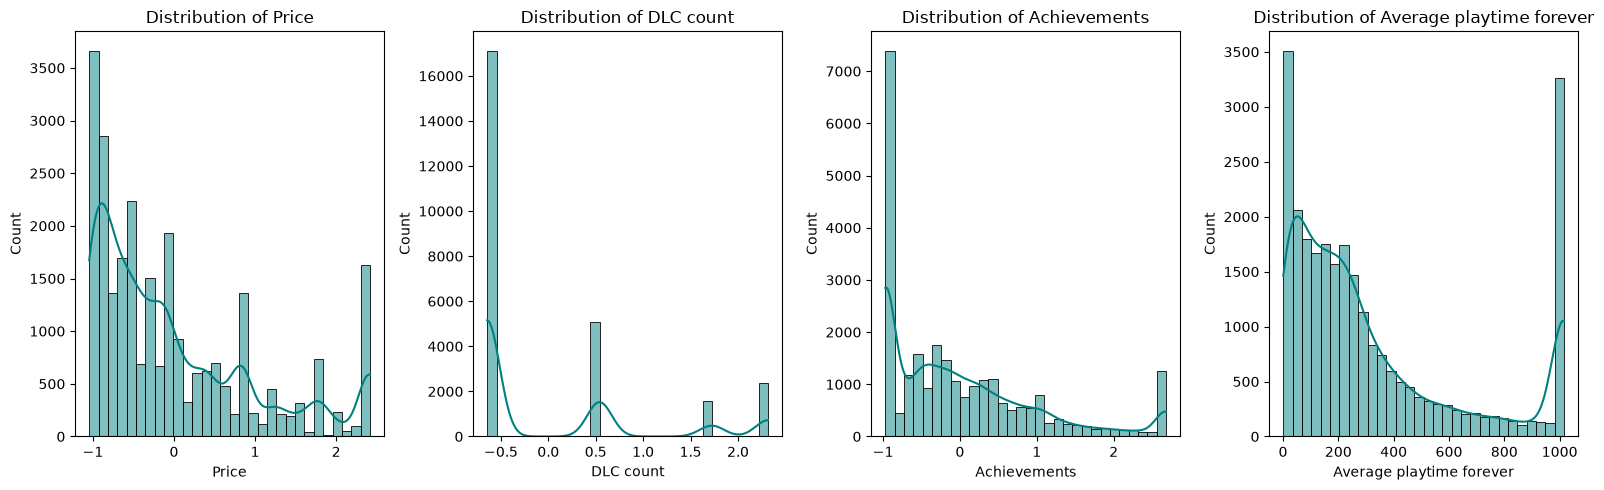

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi (KDE) untuk variabel kunci desain game
columns_to_plot = ["Price", "DLC count", "Achievements", "Average playtime forever"]

plt.figure(figsize=(16, 5))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(1, 4, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30, color="teal")
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

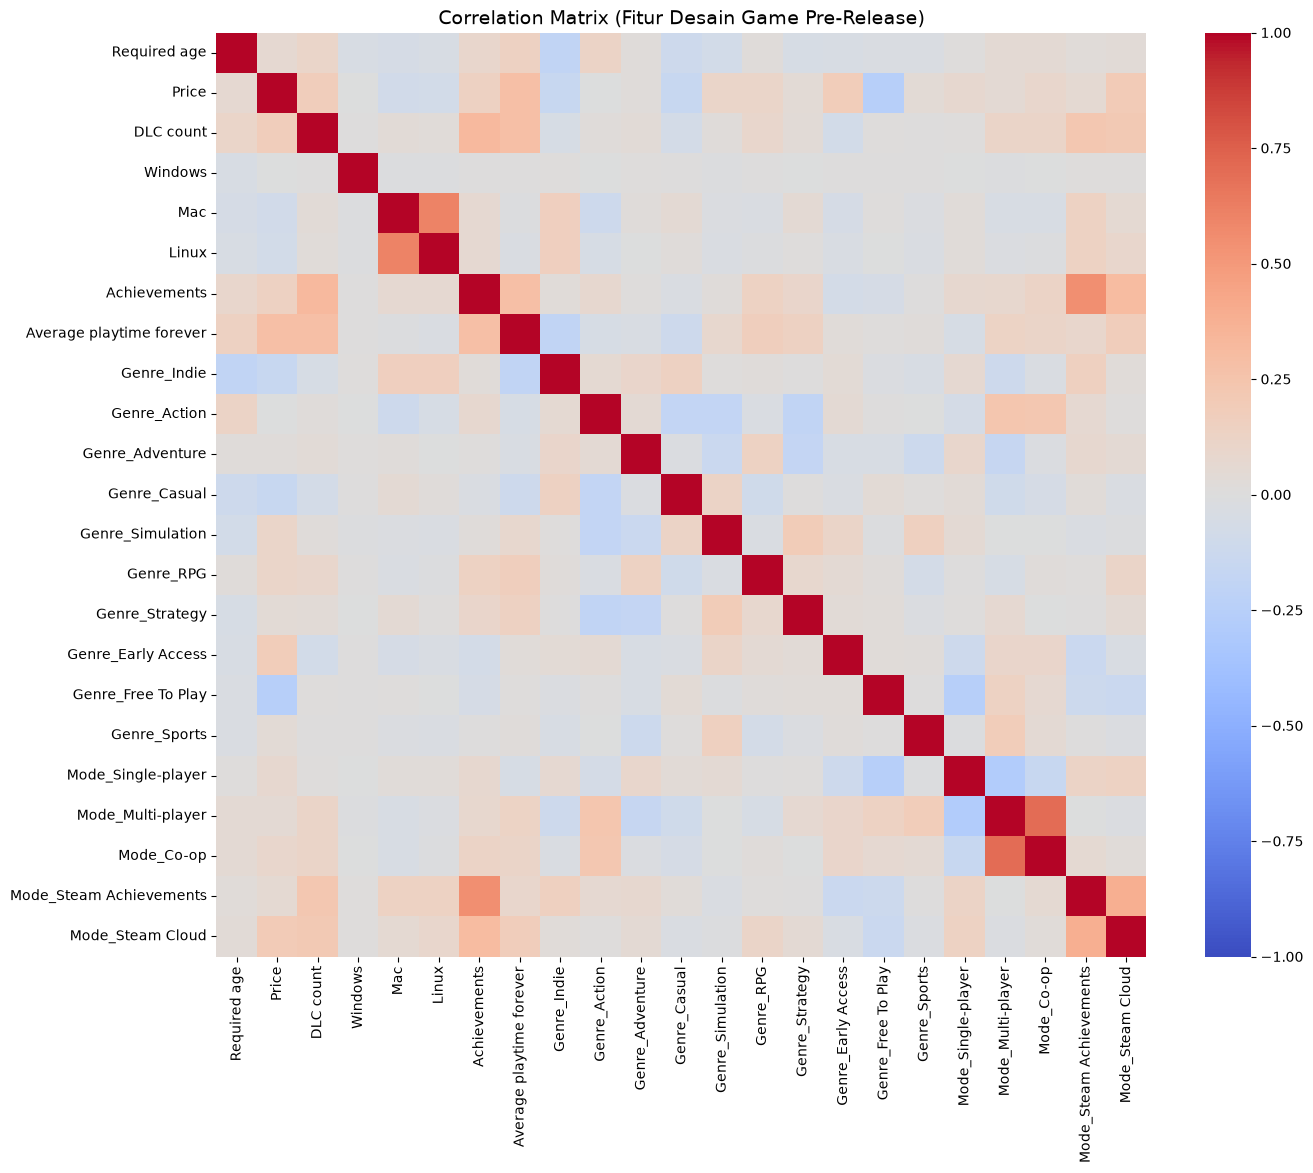

In [13]:
# Visualisasi korelasi antar seluruh variabel numerik
plt.figure(figsize=(15, 12))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix (Fitur Desain Game Pre-Release)", fontsize=14)
plt.show()

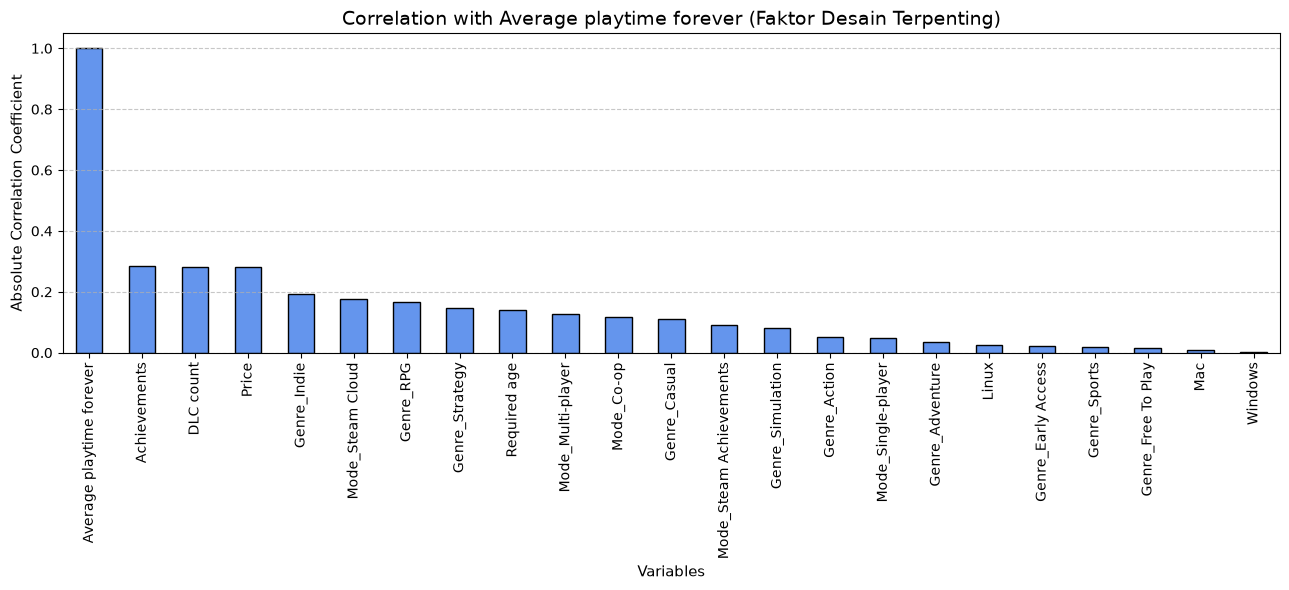


--- Nilai Korelasi Terhadap Average playtime forever ---
Average playtime forever    1.000000
Achievements                0.283673
DLC count                   0.282462
Price                       0.282392
Mode_Steam Cloud            0.175886
Genre_RPG                   0.167309
Genre_Strategy              0.146526
Required age                0.141851
Mode_Multi-player           0.127719
Mode_Co-op                  0.116938
Mode_Steam Achievements     0.090182
Genre_Simulation            0.079756
Genre_Early Access          0.023634
Genre_Sports                0.018502
Genre_Free To Play          0.014138
Windows                     0.002090
Mac                        -0.010396
Linux                      -0.026387
Genre_Adventure            -0.036367
Mode_Single-player         -0.048934
Genre_Action               -0.050252
Genre_Casual               -0.109488
Genre_Indie                -0.191295
Name: Average playtime forever, dtype: float64


In [14]:
# Menghitung korelasi terhadap variabel target (Average playtime forever)
target_corr = df_lencoder.corr()["Average playtime forever"]

# Mengurutkan hasil korelasi berdasarkan nilai absolut
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(13, 6))
target_corr_sorted.plot(kind="bar", color="cornflowerblue", edgecolor="black")
plt.title("Correlation with Average playtime forever (Faktor Desain Terpenting)", fontsize=14)
plt.xlabel("Variables", fontsize=11)
plt.ylabel("Absolute Correlation Coefficient", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("\n--- Nilai Korelasi Terhadap Average playtime forever ---")
print(target_corr.sort_values(ascending=False))

---
## Tahap 4: Data Splitting (Train & Test Split)
Membagi data menjadi 80% Latih dan 20% Uji.

In [15]:
from sklearn.model_selection import train_test_split

# 1. Memisahkan Fitur (X) dan Target (y)
X = df_lencoder.drop(columns=["Average playtime forever"])
y = df_lencoder["Average playtime forever"]

# 2. Membagi dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

# 3. Menampilkan ringkasan hasil pembagian data
print("=== Ringkasan Hasil Data Splitting ===")
print(f"Total Data Keseluruhan : {len(df_lencoder):,} baris")
print(f"Data Latih (X_train)   : {X_train.shape[0]:,} baris ({X_train.shape[0]/len(df_lencoder)*100:.1f}%) | {X_train.shape[1]} fitur")
print(f"Data Uji (X_test)      : {X_test.shape[0]:,} baris ({X_test.shape[0]/len(df_lencoder)*100:.1f}%) | {X_test.shape[1]} fitur")
print(f"Target Latih (y_train) : {y_train.shape[0]:,} baris")
print(f"Target Uji (y_test)    : {y_test.shape[0]:,} baris")

print("\nData Splitting berhasil! Data siap digunakan untuk pelatihan model Random Forest Regression.")

=== Ringkasan Hasil Data Splitting ===
Total Data Keseluruhan : 26,169 baris
Data Latih (X_train)   : 20,935 baris (80.0%) | 22 fitur
Data Uji (X_test)      : 5,234 baris (20.0%) | 22 fitur
Target Latih (y_train) : 20,935 baris
Target Uji (y_test)    : 5,234 baris

Data Splitting berhasil! Data siap digunakan untuk pelatihan model Random Forest Regression.


---
## Tahap 5 : Modeling (Random Forest Regression)


In [16]:
import time
from sklearn.ensemble import RandomForestRegressor

print("Memulai pelatihan model Random Forest Regressor...")
start_time = time.time()

# 1. Inisialisasi Model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# 2. Melatih Model dengan Data Latih
rf_model.fit(X_train, y_train)

end_time = time.time()
training_duration = end_time - start_time
print(f"Pelatihan Selesai! Waktu komputasi: {training_duration:.2f} detik.")

Memulai pelatihan model Random Forest Regressor...
Pelatihan Selesai! Waktu komputasi: 1.08 detik.


In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prediksi pada Data Uji
y_pred = rf_model.predict(X_test)

# 2. Perhitungan Metrik Evaluasi
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# 3. Menampilkan Ringkasan Evaluasi
print("=== METRIK EVALUASI PREDIKSI DURASI WAKTU BERMAIN (PRE-RELEASE MURNI) ===")
print(f"Mean Absolute Error (MAE)  : {mae:.2f} menit (~{mae/60:.2f} jam)")
print(f"Mean Squared Error (MSE)   : {mse:.2f}")
print(f"Root Mean Sq Error (RMSE)  : {rmse:.2f} menit (~{rmse/60:.2f} jam)")
print(f"R-Squared (R2 Score)       : {r2:.4f} ({r2*100:.2f}% variansi dijelaskan)")

# 4. Tabel Perbandingan 10 Sampel Nilai Aktual vs Prediksi
comparison_df = pd.DataFrame({
    "Aktual (Menit)": y_test.values[:10],
    "Prediksi (Menit)": np.round(y_pred[:10], 1),
    "Selisih (Menit)": np.round(np.abs(y_test.values[:10] - y_pred[:10]), 1),
    "Prediksi (Jam)": np.round(y_pred[:10] / 60, 2)
})
print("\n--- 10 Sampel Prediksi vs Aktual ---")
comparison_df

=== METRIK EVALUASI PREDIKSI DURASI WAKTU BERMAIN (PRE-RELEASE MURNI) ===
Mean Absolute Error (MAE)  : 215.84 menit (~3.60 jam)
Mean Squared Error (MSE)   : 82127.93
Root Mean Sq Error (RMSE)  : 286.58 menit (~4.78 jam)
R-Squared (R2 Score)       : 0.2369 (23.69% variansi dijelaskan)

--- 10 Sampel Prediksi vs Aktual ---


,Aktual (Menit),Prediksi (Menit),Selisih (Menit),Prediksi (Jam)
0,196,162.3,33.7,2.70
1,517,464.6,52.4,7.74
2,114,190.3,76.3,3.17
3,567,341.5,225.5,5.69
4,616,283.6,332.4,4.73
5,175,244.0,69.0,4.07
6,401,263.0,138.0,4.38
7,1016,665.3,350.7,11.09
8,939,876.5,62.5,14.61
9,1016,878.0,138.0,14.63


C:\Users\fajar\AppData\Local\Temp\ipykernel_83860\834943876.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Tingkat Kepentingan", y="Fitur", data=importance_df, palette="viridis")


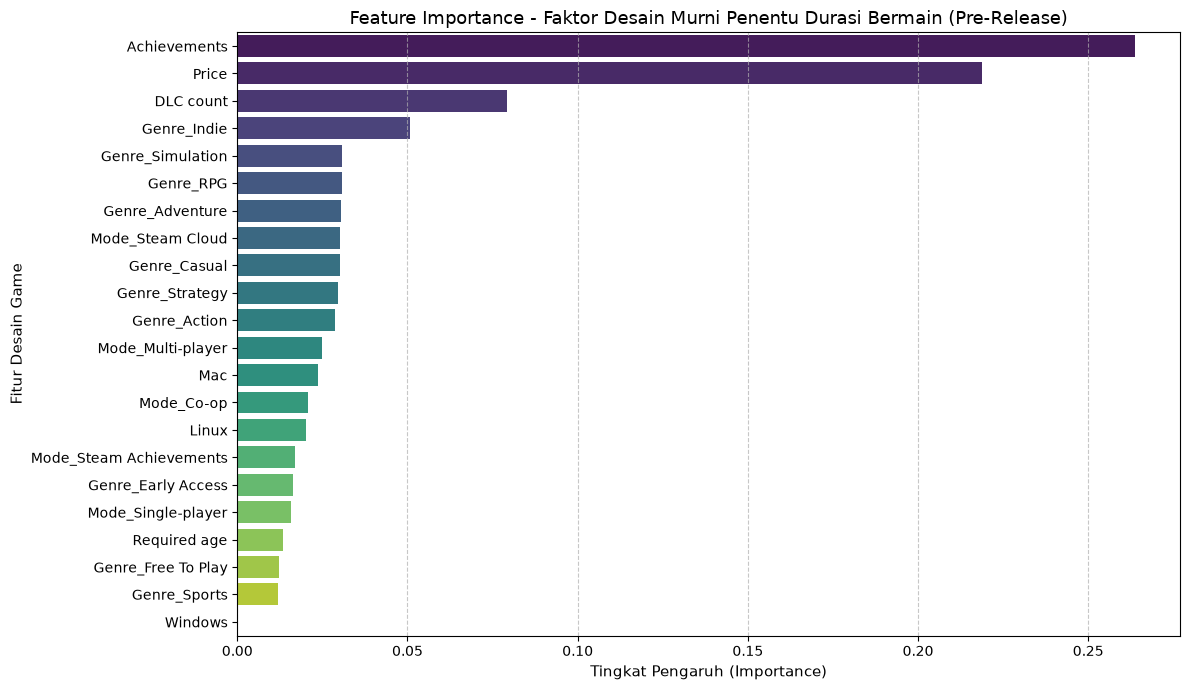

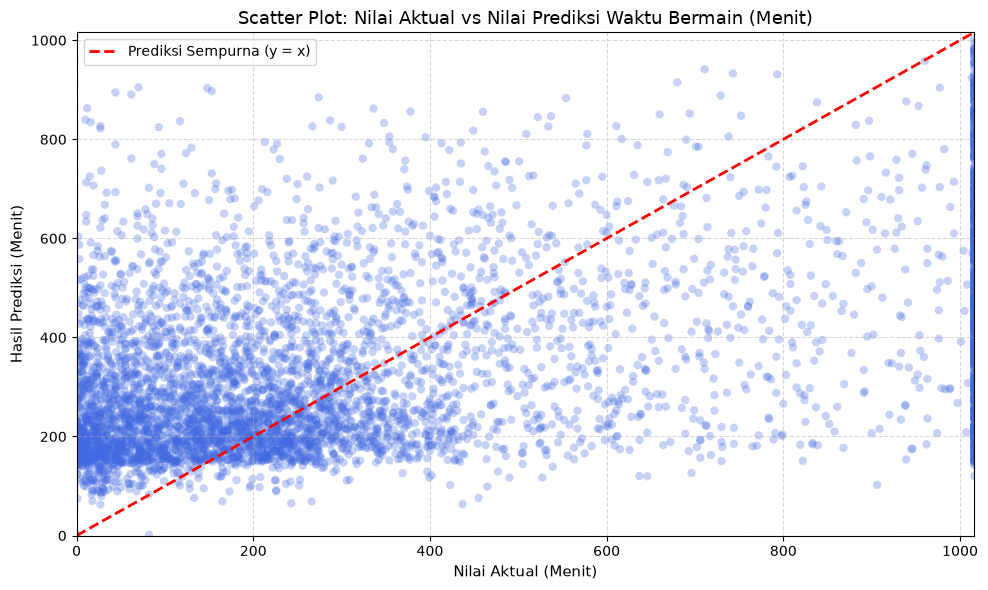

In [18]:
# 1. Menghitung Feature Importance
importance_df = pd.DataFrame({
    "Fitur": X.columns,
    "Tingkat Kepentingan": rf_model.feature_importances_
}).sort_values(by="Tingkat Kepentingan", ascending=False)

# 2. Visualisasi Diagram Batang Feature Importance
plt.figure(figsize=(12, 7))
sns.barplot(x="Tingkat Kepentingan", y="Fitur", data=importance_df, palette="viridis")
plt.title("Feature Importance - Faktor Desain Murni Penentu Durasi Bermain (Pre-Release)", fontsize=13)
plt.xlabel("Tingkat Pengaruh (Importance)", fontsize=11)
plt.ylabel("Fitur Desain Game", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Visualisasi Scatter Plot: Nilai Aktual vs Nilai Prediksi
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color="royalblue", edgecolors="none")
max_val = min(max(y_test.max(), y_pred.max()), 1200)
plt.plot([0, max_val], [0, max_val], color="red", linestyle="--", linewidth=2, label="Prediksi Sempurna (y = x)")
plt.xlim(0, max_val)
plt.ylim(0, max_val)
plt.title("Scatter Plot: Nilai Aktual vs Nilai Prediksi Waktu Bermain (Menit)", fontsize=13)
plt.xlabel("Nilai Aktual (Menit)", fontsize=11)
plt.ylabel("Hasil Prediksi (Menit)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()